# 01 · Qualidade dos dados e governança

**Pergunta:** os dados são confiáveis o suficiente para embasar decisões de investimento? Que recortes e tratamentos precisam ser feitos antes da análise?

Este notebook documenta o inventário das tabelas, a integridade entre elas, os problemas encontrados e as decisões tomadas. As decisões ficam centralizadas em `src/olist/config.py` e `src/olist/prep.py`, para que todos os notebooks partam da mesma base.

## Principais conclusões

- **A base é confiável.** As chaves das tabelas não se repetem, o valor pago bate com preço + frete em 99,7% dos pedidos e as inconsistências de datas atingem cerca de 1,4% dos pedidos.
- **Janela de análise: jan/2017 a ago/2018**, com 99,6% dos pedidos. O volume diário despenca a partir de 22/08/2018 por causa do **corte da extração**, então as séries mensais vão até jul/2018.
- **Tratamentos principais:** o cliente é identificado pelo `customer_unique_id` (3.345 IDs consolidados), fica uma avaliação por pedido (547 duplicadas) e a receita é medida por preço + frete dos itens, excluindo os 1.234 pedidos cancelados ou indisponíveis.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from olist import config, data, prep, viz
from olist.viz import CORES, brl, num, pct

viz.aplicar_estilo()

In [2]:
t = data.carregar_todas(incluir_geolocalizacao=True)
o, itens, pag, rev = t["orders"], t["order_items"], t["payments"], t["reviews"]
cli, prod, geo = t["customers"], t["products"], t["geolocation"]

## 1. Inventário das tabelas

São 9 tabelas ligadas pelo `order_id` (pedido), `customer_id` (cliente), `product_id` (produto) e `seller_id` (vendedor). A coluna `chave_unica` confirma se a chave primária esperada de fato não se repete.

In [3]:
chaves = {
    "customers": ["customer_id"],
    "order_items": ["order_id", "order_item_id"],
    "payments": ["order_id", "payment_sequential"],
    "reviews": ["review_id", "order_id"],
    "orders": ["order_id"],
    "products": ["product_id"],
    "sellers": ["seller_id"],
    "category_translation": ["product_category_name"],
}
inventario = pd.DataFrame([
    {
        "tabela": nome,
        "linhas": num(len(df)),
        "colunas": df.shape[1],
        "chave": " + ".join(chaves.get(nome, ["—"])),
        "chave_unica": "sim" if nome in chaves and not df.duplicated(chaves[nome]).any() else "não se aplica" if nome not in chaves else "NÃO",
        "% células vazias": round(df.isna().mean().mean() * 100, 2),
    }
    for nome, df in t.items()
])
inventario

,tabela,linhas,colunas,chave,chave_unica,% células vazias
0,customers,99.441,5,customer_id,sim,0.00
1,geolocation,1.000.163,5,—,não se aplica,0.00
2,order_items,112.650,7,order_id + order_item_id,sim,0.00
3,payments,103.886,5,order_id + payment_sequential,sim,0.00
4,reviews,99.224,7,review_id + order_id,sim,21.01
5,orders,99.441,8,order_id,sim,0.62
6,products,32.951,9,product_id,sim,0.83
7,sellers,3.095,4,seller_id,sim,0.00
8,category_translation,71,2,product_category_name,sim,0.00


## 2. Integridade entre as tabelas

In [4]:
traduzidas = set(t["category_translation"].product_category_name)
categorias = prod.product_category_name.dropna().drop_duplicates()

integridade = pd.DataFrame([
    ("Pedidos sem itens", (~o.order_id.isin(itens.order_id)).sum(), len(o), "Ficam fora das métricas de receita"),
    ("Pedidos sem pagamento", (~o.order_id.isin(pag.order_id)).sum(), len(o), "Sem impacto relevante"),
    ("Pedidos sem avaliação", (~o.order_id.isin(rev.order_id)).sum(), len(o), "Ficam fora das análises de satisfação"),
    ("Pedidos com mais de uma avaliação", rev.order_id.value_counts().gt(1).sum(), len(o), "Mantida a avaliação mais recente"),
    ("Produtos sem categoria", prod.product_category_name.isna().sum(), len(prod), "Agrupados como 'Sem categoria'"),
    ("Categorias sem tradução", (~categorias.isin(traduzidas)).sum(), len(categorias), "Usamos o nome em português"),
    ("CEPs de clientes sem coordenadas", (~cli.customer_zip_code_prefix.isin(geo.geolocation_zip_code_prefix)).sum(), len(cli), "Coordenadas não usadas nas métricas"),
], columns=["verificação", "ocorrências", "base", "tratamento"])
integridade["% da base"] = (integridade["ocorrências"] / integridade["base"] * 100).round(2)
integridade

,verificação,ocorrências,base,tratamento,% da base
0,Pedidos sem itens,775,99441,Ficam fora das métricas de receita,0.78
1,Pedidos sem pagamento,1,99441,Sem impacto relevante,0.00
2,Pedidos sem avaliação,768,99441,Ficam fora das análises de satisfação,0.77
3,Pedidos com mais de uma avaliação,547,99441,Mantida a avaliação mais recente,0.55
4,Produtos sem categoria,610,32951,Agrupados como 'Sem categoria',1.85
5,Categorias sem tradução,2,73,Usamos o nome em português,2.74
6,CEPs de clientes sem coordenadas,278,99441,Coordenadas não usadas nas métricas,0.28


In [5]:
print("Status dos pedidos sem itens:")
o.loc[~o.order_id.isin(itens.order_id), "order_status"].value_counts()

Status dos pedidos sem itens:


order_status
unavailable    603
canceled       164
created          5
invoiced         2
shipped          1
Name: count, dtype: int64

**Identidade do cliente.** A tabela de clientes tem um `customer_id` por pedido. A pessoa é identificada pelo `customer_unique_id`. Usar o `customer_id` faria todo cliente parecer novo e esconderia a recompra.

In [6]:
print(f"customer_id distintos:        {num(cli.customer_id.nunique())}")
print(f"customer_unique_id distintos: {num(cli.customer_unique_id.nunique())}")

customer_id distintos:        99.441
customer_unique_id distintos: 96.096


## 3. Valores ausentes

In [7]:
ausentes = pd.concat({nome: df.isna().mean() for nome, df in t.items()}).mul(100).round(2)
ausentes[ausentes > 0].rename("% ausente").to_frame()

% ausente
reviews  review_comment_title               88.34
         review_comment_message             58.70
orders   order_approved_at                   0.16
         order_delivered_carrier_date        1.79
         order_delivered_customer_date       2.98
products product_category_name               1.85
         product_name_lenght                 1.85
         product_description_lenght          1.85
         product_photos_qty                  1.85
         product_weight_g                    0.01
         product_length_cm                   0.01
         product_height_cm                   0.01
         product_width_cm                    0.01

Os comentários das avaliações são opcionais, então a ausência é esperada. As datas ausentes de aprovação, postagem e entrega correspondem a pedidos que não chegaram a essas etapas (cancelados, em trânsito etc.).

## 4. Consistência de datas

In [8]:
datas = pd.DataFrame([
    ("Aprovação antes da compra", (o.order_approved_at < o.order_purchase_timestamp).sum()),
    ("Postagem antes da aprovação", (o.order_delivered_carrier_date < o.order_approved_at).sum()),
    ("Entrega antes da postagem", (o.order_delivered_customer_date < o.order_delivered_carrier_date).sum()),
    ("Status 'entregue' sem data de entrega", ((o.order_status == "delivered") & o.order_delivered_customer_date.isna()).sum()),
    ("Data de entrega em pedido não entregue", ((o.order_status != "delivered") & o.order_delivered_customer_date.notna()).sum()),
], columns=["inconsistência", "pedidos"])
datas["% dos pedidos"] = (datas.pedidos / len(o) * 100).round(2)
datas

,inconsistência,pedidos,% dos pedidos
0,Aprovação antes da compra,0,0.00
1,Postagem antes da aprovação,1359,1.37
2,Entrega antes da postagem,23,0.02
3,Status 'entregue' sem data de entrega,8,0.01
4,Data de entrega em pedido não entregue,6,0.01


As inconsistências atingem menos de 2% dos pedidos. Na decomposição do prazo (notebook 03), etapas com duração negativa são descartadas; o prazo total (compra → entrega) não é afetado.

## 5. Consistência financeira

Comparamos o valor pago com a soma de preço + frete dos itens de cada pedido.

In [9]:
valor_itens = itens.assign(total=itens.price + itens.freight_value).groupby("order_id").total.sum()
valor_pago = pag.groupby("order_id").payment_value.sum()
comp = pd.concat([valor_itens.rename("itens_mais_frete"), valor_pago.rename("pago")], axis=1, join="inner")
comp["diferenca"] = comp.pago - comp.itens_mais_frete

pago_sem_itens = pag.loc[~pag.order_id.isin(itens.order_id), "payment_value"].sum()

print(f"Pedidos com diferença de até R$ 1:        {pct((comp.diferenca.abs() <= 1).mean())}")
print(f"Pedidos pagos acima do valor dos itens:    {pct((comp.diferenca > 1).mean())}")
print(f"Pedidos pagos abaixo do valor dos itens:   {pct((comp.diferenca < -1).mean())}")
print(f"Diferença total nos pedidos com itens:     {brl(comp.diferenca.sum())}")
print(f"Pagamentos de pedidos sem itens:           {brl(pago_sem_itens)}")

Pedidos com diferença de até R$ 1:        99,7%
Pedidos pagos acima do valor dos itens:    0,2%
Pedidos pagos abaixo do valor dos itens:   0,0%
Diferença total nos pedidos com itens:     R$ 3 mil
Pagamentos de pedidos sem itens:           R$ 163 mil


In [10]:
parcelas = pag.groupby("order_id").payment_installments.max()
comp = comp.join(parcelas.rename("parcelas"))
faixa = pd.cut(comp.parcelas, [-1, 1, 3, 6, 10, 24], labels=["à vista", "2–3x", "4–6x", "7–10x", "11x+"])
comp.groupby(faixa, observed=True).diferenca.agg(
    pedidos="size",
    pago_acima=lambda d: pct((d > 1).mean()),
    diferenca_media=lambda d: brl(d.mean()),
)

,pedidos,pago_acima,diferenca_media
parcelas,,,
à vista,47825,"0,0%",R$ -0
2–3x,22662,"0,2%",R$ 0
4–6x,16097,"0,6%",R$ 0
7–10x,11744,"0,6%",R$ 0
11x+,337,"7,1%",R$ 2


Os valores batem em 99,7% dos pedidos. Só nos parcelamentos em 11 vezes ou mais aparece um pequeno acréscimo, compatível com juros. A diferença relevante no total vem de **pagamentos registrados em pedidos sem itens** (quase todos indisponíveis ou cancelados), que não representam venda.

Por isso a receita (GMV) é medida por **preço + frete dos itens dos pedidos válidos**, e não pela soma dos pagamentos.

## 6. Valores extremos

In [11]:
print(itens[["price", "freight_value"]].describe(percentiles=[0.5, 0.9, 0.99]).T)
print()
print(f"Itens com frete zero:   {num((itens.freight_value == 0).sum())}")
print(f"Produtos com peso zero: {num((prod.product_weight_g == 0).sum())}")

                   count   mean    std  min   50%    90%    99%      max
price         112,650.00 120.65 183.63 0.85 74.99 229.80 890.00 6,735.00
freight_value 112,650.00  19.99  15.81 0.00 16.26  34.04  84.52   409.68

Itens com frete zero:   383
Produtos com peso zero: 4


Os preços altos (até R$ 6.735) são legítimos: eletrônicos, móveis e relógios. Não removemos esses valores; nas análises de satisfação e prazo usamos médias e medianas por grupo, que são pouco sensíveis a eles.

## 7. Geolocalização

In [12]:
fora_do_brasil = ~geo.geolocation_lat.between(-34, 5.3) | ~geo.geolocation_lng.between(-74, -34.7)
print(f"Linhas na tabela de geolocalização: {num(len(geo))}")
print(f"Prefixos de CEP distintos:          {num(geo.geolocation_zip_code_prefix.nunique())}")
print(f"Coordenadas fora do Brasil:         {num(fora_do_brasil.sum())}")

Linhas na tabela de geolocalização: 1.000.163
Prefixos de CEP distintos:          19.015
Coordenadas fora do Brasil:         42


Há vários pontos por CEP e algumas coordenadas fora do território nacional. Como a UF e a cidade já estão nas tabelas de clientes e vendedores, a geolocalização não é usada nas métricas.

## 8. Status dos pedidos

In [13]:
status = o.order_status.value_counts().to_frame("pedidos")
status["%"] = (status.pedidos / len(o) * 100).round(2)
status

,pedidos,%
order_status,,
delivered,96478,97.02
shipped,1107,1.11
canceled,625,0.63
unavailable,609,0.61
invoiced,314,0.32
processing,301,0.30
created,5,0.01
approved,2,0.00


## 9. Cobertura temporal e janela de análise

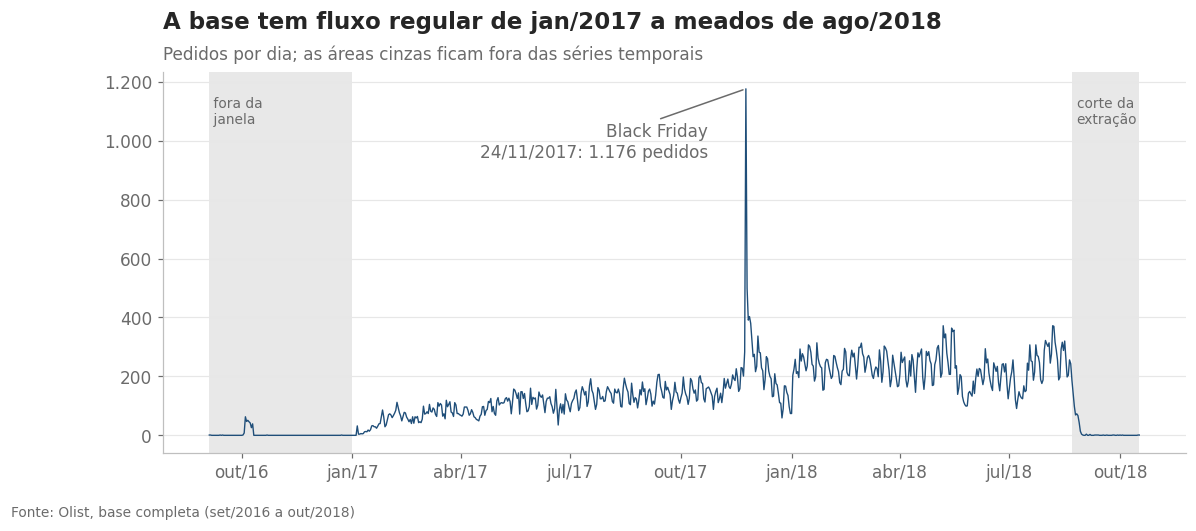

In [14]:
diario = o.set_index("order_purchase_timestamp").resample("D").size()
inicio, fim = pd.Timestamp(config.INICIO_JANELA), pd.Timestamp(config.FIM_SERIE_DIARIA)
bf = diario.idxmax()

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(diario.index, diario.values, color=CORES["principal"], lw=0.9)
ax.axvspan(diario.index.min(), inicio, color=CORES["neutro"], alpha=0.25, lw=0)
ax.axvspan(fim + pd.Timedelta(days=1), diario.index.max(), color=CORES["neutro"], alpha=0.25, lw=0)
ax.annotate(f"Black Friday\n{bf:%d/%m/%Y}: {num(diario[bf])} pedidos", xy=(bf, diario[bf]), xytext=(-25, -45),
            textcoords="offset points", ha="right", arrowprops=dict(arrowstyle="-", color=CORES["subtexto"]), color=CORES["subtexto"])
ax.text(diario.index.min(), diario.max() * 0.9, " fora da\n janela", color=CORES["subtexto"], fontsize=9)
ax.text(fim + pd.Timedelta(days=5), diario.max() * 0.9, "corte da\nextração", color=CORES["subtexto"], fontsize=9)
ax.yaxis.set_major_formatter(viz.eixo_num)
ax.xaxis.set_major_formatter(viz.eixo_mes)
viz.titulo(ax, "A base tem fluxo regular de jan/2017 a meados de ago/2018",
           "Pedidos por dia; as áreas cinzas ficam fora das séries temporais")
viz.fonte(fig, "Fonte: Olist, base completa (set/2016 a out/2018)")
viz.salvar(fig, "01_cobertura_temporal")

In [15]:
print("Pedidos por dia no fim da base:")
diario.loc["2018-08-15":"2018-08-31"].rename_axis("dia").to_frame("pedidos")

Pedidos por dia no fim da base:


,pedidos
dia,
2018-08-15,288
2018-08-16,320
2018-08-17,257
2018-08-18,198
2018-08-19,204
2018-08-20,256
2018-08-21,243
2018-08-22,187
2018-08-23,144


O volume diário cai de cerca de 250 pedidos para quase zero entre 22 e 31/08/2018 e não se recupera. Esse comportamento é típico de um **corte na extração dos dados**, e não de uma queda real das vendas. Por isso:

- as **séries mensais** vão de jan/2017 a jul/2018 (19 meses completos);
- a **série diária** usada na previsão vai até 21/08/2018;
- análises que não dependem do tempo (logística, satisfação, clientes) usam todos os pedidos de jan/2017 a ago/2018.

## 10. Resumo das decisões

In [16]:
fora_janela = ~prep.no_periodo(o.order_purchase_timestamp, config.INICIO_JANELA, config.FIM_JANELA)
multi_avaliacao = rev.order_id.value_counts().gt(1).sum()
multi_item = (itens.groupby("order_id").size() > 1).mean()

decisoes = pd.DataFrame([
    ("Janela de análise: jan/2017 a ago/2018",
     "2016 foi uma fase inicial (sem vendas em nov/2016) e após ago/2018 há só resíduos",
     f"{num(fora_janela.sum())} pedidos fora ({pct(fora_janela.mean())})"),
    ("Séries mensais até jul/2018; série diária até 21/08/2018",
     "Volume despenca a partir de 22/08/2018 (corte da extração)",
     "Agosto/2018 só entra onde o mês parcial não distorce"),
    ("Receita (GMV) = preço + frete dos itens",
     "Há pagamentos registrados em pedidos sem itens, que não viraram venda",
     f"{brl(pago_sem_itens)} em pagamentos desconsiderados"),
    ("Pedidos cancelados ou indisponíveis fora da receita",
     "Não geraram venda",
     f"{num(o.order_status.isin(config.STATUS_INVALIDOS).sum())} pedidos"),
    ("Uma avaliação por pedido (a mais recente)",
     "Alguns pedidos foram avaliados mais de uma vez",
     f"{num(multi_avaliacao)} pedidos"),
    ("Cliente = customer_unique_id",
     "O customer_id muda a cada pedido",
     f"{num(cli.customer_id.nunique() - cli.customer_unique_id.nunique())} IDs consolidados"),
    ("Atraso = entrega em dia posterior à data prometida",
     "A data prometida não tem horário",
     "Critério conservador (não conta como atraso a entrega no próprio dia)"),
    ("Categoria e vendedor do pedido = item de maior valor",
     "Pedidos podem ter vários itens",
     f"{pct(multi_item)} dos pedidos têm 2+ itens"),
    ("Coordenadas geográficas não usadas",
     "Vários pontos por CEP e pontos fora do Brasil",
     "UF e cidade vêm das tabelas de clientes e vendedores"),
], columns=["decisão", "motivo", "impacto"])
decisoes

,decisão,motivo,impacto
0,Janela de análise: jan/2017 a ago/2018,2016 foi uma fase inicial (sem vendas em nov/2016) e após ago/2018 há só resíduos,"349 pedidos fora (0,4%)"
1,Séries mensais até jul/2018; série diária até 21/08/2018,Volume despenca a partir de 22/08/2018 (corte da extração),Agosto/2018 só entra onde o mês parcial não distorce
2,Receita (GMV) = preço + frete dos itens,"Há pagamentos registrados em pedidos sem itens, que não viraram venda",R$ 163 mil em pagamentos desconsiderados
3,Pedidos cancelados ou indisponíveis fora da receita,Não geraram venda,1.234 pedidos
4,Uma avaliação por pedido (a mais recente),Alguns pedidos foram avaliados mais de uma vez,547 pedidos
5,Cliente = customer_unique_id,O customer_id muda a cada pedido,3.345 IDs consolidados
6,Atraso = entrega em dia posterior à data prometida,A data prometida não tem horário,Critério conservador (não conta como atraso a entrega no próprio dia)
7,Categoria e vendedor do pedido = item de maior valor,Pedidos podem ter vários itens,"9,9% dos pedidos têm 2+ itens"
8,Coordenadas geográficas não usadas,Vários pontos por CEP e pontos fora do Brasil,UF e cidade vêm das tabelas de clientes e vendedores


## 11. Base analítica

A função `prep.carregar_base_pedidos()` aplica todas as decisões acima e gera uma linha por pedido, salva em `data/processed/base_pedidos.parquet` para os próximos notebooks.

In [17]:
pedidos = prep.carregar_base_pedidos(recriar=True)
print(f"{num(len(pedidos))} pedidos na janela, {pedidos.shape[1]} colunas")
print(f"Válidos para receita: {num(pedidos.valido.sum())} | Entregues: {num(pedidos.entregue.sum())} | Avaliados: {num(pedidos.review_score.notna().sum())}")
pedidos.head(3).T

99.092 pedidos na janela, 44 colunas
Válidos para receita: 97.905 | Entregues: 96.203 | Avaliados: 98.330


,0,1,2
order_id,e481f51cbdc54678b7cc49136f2d6af7,53cdb2fc8bc7dce0b6741e2150273451,47770eb9100c2d0c44946d9cf07ec65d
customer_id,9ef432eb6251297304e76186b10a928d,b0830fb4747a6c6d20dea0b8c802d7ef,41ce2a54c0b03bf3443c3d931a367089
order_status,delivered,delivered,delivered
order_purchase_timestamp,2017-10-02 10:56:33,2018-07-24 20:41:37,2018-08-08 08:38:49
order_approved_at,2017-10-02 11:07:15,2018-07-26 03:24:27,2018-08-08 08:55:23
order_delivered_carrier_date,2017-10-04 19:55:00,2018-07-26 14:31:00,2018-08-08 13:50:00
order_delivered_customer_date,2017-10-10 21:25:13,2018-08-07 15:27:45,2018-08-17 18:06:29
order_estimated_delivery_date,2017-10-18 00:00:00,2018-08-13 00:00:00,2018-09-04 00:00:00
customer_unique_id,7c396fd4830fd04220f754e42b4e5bff,af07308b275d755c9edb36a90c618231,3a653a41f6f9fc3d2a113cf8398680e8
customer_zip_code_prefix,03149,47813,75265
